# TP : modèles discriminatifs et génératifs sur MNIST

Ce TP charge les chiffres manuscrits MNIST, entraîne un classificateur, un auto-encodeur simple et un auto-encodeur variationnel (VAE), puis compare leurs résultats et explore l'espace latent.

**Préparation :** synchroniser le projet avec `uv sync --python 3.11`, sélectionner le noyau `.venv` dans VS Code, puis exécuter les cellules dans l'ordre. Le premier chargement de MNIST nécessite Internet. Les modèles utilisent CUDA si disponible, sinon CPU. Les trois époques par défaut limitent le temps d'attente sur CPU ; les constantes d'entraînement peuvent être augmentées.

In [1]:
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torcheval.metrics.functional import multiclass_accuracy

SEED = 42
BATCH_SIZE = 256
EPOCHS_CLASSIFIEUR = 3
EPOCHS_AUTOENCODEUR = 3
EPOCHS_VAE = 3
LATENT_DIM = 2

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | appareil : {device}")

c:\Users\sbaii\OneDrive\IA Générative Multi Modale\lab_pytorch_v1\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch 2.14.1+cpu | appareil : cpu


## 1. Charger et explorer MNIST

`ToTensor` convertit les images en tenseurs flottants de forme `(1, 28, 28)` et normalise les pixels dans `[0, 1]`. Cette plage convient à la sortie sigmoïde des auto-encodeurs.

In [2]:
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="data", train=False, download=True, transform=transform)

# num_workers=0 est compatible avec l'exécution des notebooks sous Windows.
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=loader_generator,
)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print(f"Entraînement : {len(train_dataset):,} images | Test : {len(test_dataset):,} images")
print(f"Forme d'un lot : {tuple(images.shape)} | type : {images.dtype}")
print(f"Valeurs des pixels : [{images.min().item():.1f}, {images.max().item():.1f}]")
print(f"Étiquettes présentes dans le premier lot : {torch.unique(labels).tolist()}")

100.0%
100.0%
100.0%
100.0%


Entraînement : 60,000 images | Test : 10,000 images
Forme d'un lot : (256, 1, 28, 28) | type : torch.float32
Valeurs des pixels : [0.0, 1.0]
Étiquettes présentes dans le premier lot : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


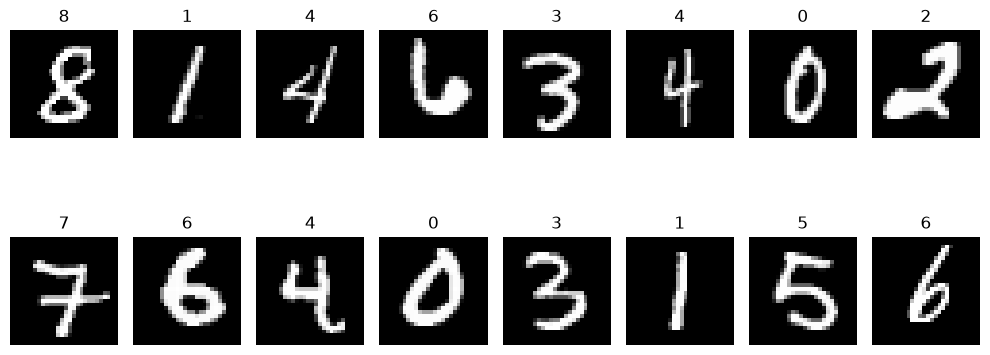

In [3]:
def show_images(images, titles=None, columns=8, figsize=(10, 5)):
    """Affiche une série d'images MNIST (tenseurs de forme 1x28x28)."""
    images = images.detach().cpu()
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=figsize, squeeze=False)
    for index, ax in enumerate(axes.flat):
        ax.axis("off")
        if index < len(images):
            ax.imshow(images[index].squeeze(), cmap="gray", vmin=0, vmax=1)
            if titles is not None:
                ax.set_title(str(titles[index]))
    plt.tight_layout()
    plt.show()


show_images(images[:16], titles=labels[:16].tolist(), columns=8)

## 2. Modèle discriminatif : classifier les chiffres

Le réseau reçoit les 784 pixels aplatis et prédit 10 scores (un par chiffre). `CrossEntropyLoss` attend ces scores bruts et les étiquettes entières ; il ne faut donc pas appliquer de softmax dans le modèle.

In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.network(x)


classifier = Classifier().to(device)
classifier_optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
classification_loss = nn.CrossEntropyLoss()


def evaluate_classifier(model, loader):
    model.eval()
    loss_sum = 0.0
    all_predictions, all_targets = [], []
    with torch.inference_mode():
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)
            logits = model(batch_images)
            loss_sum += classification_loss(logits, batch_labels).item() * len(batch_labels)
            all_predictions.append(logits.argmax(dim=1).cpu())
            all_targets.append(batch_labels.cpu())
    predictions = torch.cat(all_predictions)
    targets = torch.cat(all_targets)
    accuracy = multiclass_accuracy(predictions, targets).item()
    confusion = torch.bincount(
        10 * targets + predictions, minlength=10 * 10
    ).reshape(10, 10)
    return loss_sum / len(loader.dataset), accuracy, confusion


classifier_train_losses = []
classifier_test_losses = []
for epoch in range(EPOCHS_CLASSIFIEUR):
    classifier.train()
    loss_sum = 0.0
    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)
        classifier_optimizer.zero_grad()
        loss = classification_loss(classifier(batch_images), batch_labels)
        loss.backward()
        classifier_optimizer.step()
        loss_sum += loss.item() * len(batch_labels)
    train_loss = loss_sum / len(train_dataset)
    test_loss, test_accuracy, _ = evaluate_classifier(classifier, test_loader)
    classifier_train_losses.append(train_loss)
    classifier_test_losses.append(test_loss)
    print(
        f"Époque {epoch + 1}/{EPOCHS_CLASSIFIEUR} | "
        f"perte entraînement : {train_loss:.4f} | "
        f"perte test : {test_loss:.4f} | exactitude test : {test_accuracy:.2%}"
    )

Époque 1/3 | perte entraînement : 0.4494 | perte test : 0.2301 | exactitude test : 93.30%
Époque 2/3 | perte entraînement : 0.1988 | perte test : 0.1696 | exactitude test : 94.83%
Époque 3/3 | perte entraînement : 0.1437 | perte test : 0.1320 | exactitude test : 96.33%


Résultat final sur les données de test : perte=0.1320, exactitude=96.33%


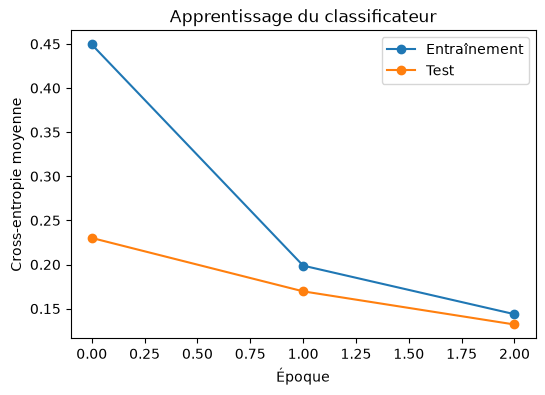

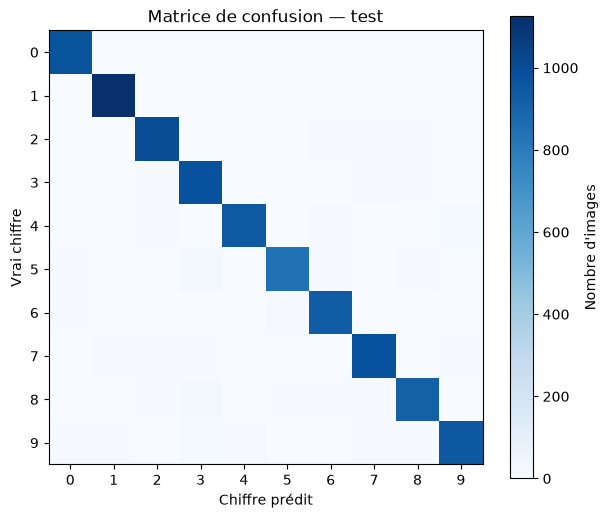

In [5]:
final_test_loss, final_test_accuracy, confusion = evaluate_classifier(classifier, test_loader)
print(f"Résultat final sur les données de test : perte={final_test_loss:.4f}, exactitude={final_test_accuracy:.2%}")

plt.figure(figsize=(6, 4))
plt.plot(classifier_train_losses, marker="o", label="Entraînement")
plt.plot(classifier_test_losses, marker="o", label="Test")
plt.xlabel("Époque")
plt.ylabel("Cross-entropie moyenne")
plt.title("Apprentissage du classificateur")
plt.legend()
plt.show()

plt.figure(figsize=(7, 6))
plt.imshow(confusion, cmap="Blues")
plt.colorbar(label="Nombre d'images")
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Chiffre prédit")
plt.ylabel("Vrai chiffre")
plt.title("Matrice de confusion — test")
plt.show()

## 3. Auto-encodeur simple : reconstruire les chiffres

L'encodeur compresse l'image en un code de 32 valeurs ; le décodeur tente de reconstruire les 784 pixels. L'apprentissage est non supervisé : la cible est l'image elle-même, pas son étiquette.

In [6]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()
        )

    def forward(self, x):
        code = self.encoder(x)
        reconstruction = self.decoder(code).reshape(-1, 1, 28, 28)
        return reconstruction, code


autoencoder = Autoencoder(latent_dim=32).to(device)
autoencoder_optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)
reconstruction_loss = nn.BCELoss(reduction="sum")


def run_autoencoder_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = 0.0
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for batch_images, _ in loader:
            batch_images = batch_images.to(device)
            if training:
                optimizer.zero_grad()
            reconstructed, _ = model(batch_images)
            loss = reconstruction_loss(reconstructed, batch_images)
            if training:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item()
    return loss_sum / len(loader.dataset)


autoencoder_train_losses, autoencoder_test_losses = [], []
for epoch in range(EPOCHS_AUTOENCODEUR):
    train_loss = run_autoencoder_epoch(autoencoder, train_loader, autoencoder_optimizer)
    test_loss = run_autoencoder_epoch(autoencoder, test_loader)
    autoencoder_train_losses.append(train_loss)
    autoencoder_test_losses.append(test_loss)
    print(
        f"Époque {epoch + 1}/{EPOCHS_AUTOENCODEUR} | "
        f"BCE entraînement / image : {train_loss:.2f} | test : {test_loss:.2f}"
    )

Époque 1/3 | BCE entraînement / image : 174.87 | test : 114.28
Époque 2/3 | BCE entraînement / image : 101.37 | test : 90.15
Époque 3/3 | BCE entraînement / image : 86.19 | test : 81.68


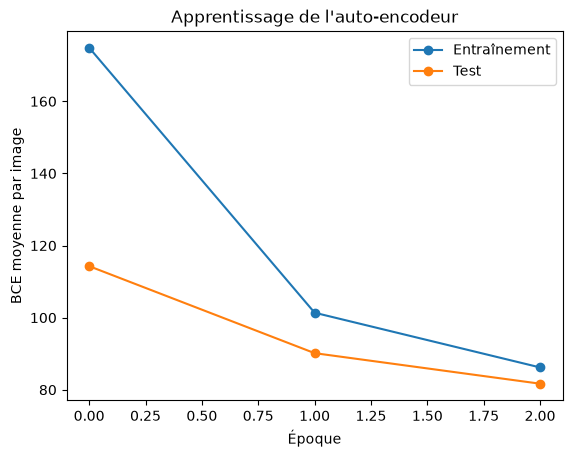

Ligne du haut : images originales ; ligne du bas : reconstructions


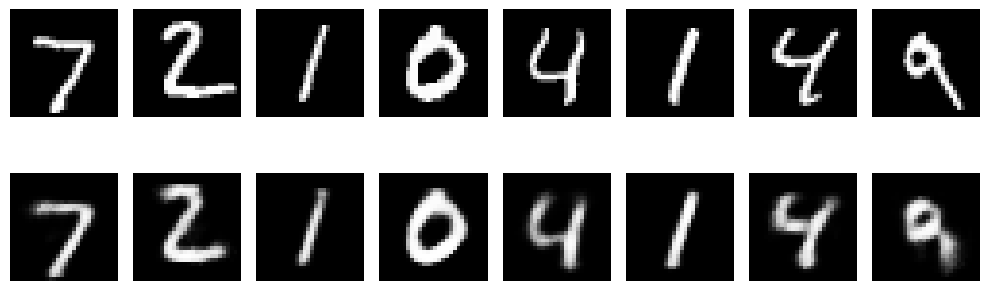

In [7]:
plt.plot(autoencoder_train_losses, marker="o", label="Entraînement")
plt.plot(autoencoder_test_losses, marker="o", label="Test")
plt.xlabel("Époque")
plt.ylabel("BCE moyenne par image")
plt.title("Apprentissage de l'auto-encodeur")
plt.legend()
plt.show()

sample_images, sample_labels = next(iter(test_loader))
autoencoder.eval()
with torch.inference_mode():
    reconstructions, codes = autoencoder(sample_images.to(device))
print("Ligne du haut : images originales ; ligne du bas : reconstructions")
show_images(torch.cat([sample_images[:8], reconstructions[:8].cpu()]), columns=8, figsize=(10, 4))

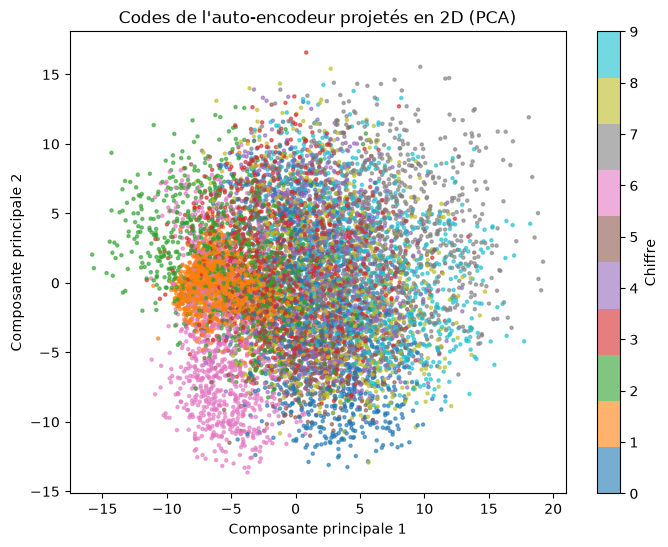

In [8]:
# Projection illustrative des codes de 2 dimensions (PCA calculée avec PyTorch).
autoencoder.eval()
latent_batches, label_batches = [], []
with torch.inference_mode():
    for batch_images, batch_labels in test_loader:
        _, batch_codes = autoencoder(batch_images.to(device))
        latent_batches.append(batch_codes.cpu())
        label_batches.append(batch_labels)
latent_codes = torch.cat(latent_batches)
latent_labels = torch.cat(label_batches)
centered_codes = latent_codes - latent_codes.mean(dim=0, keepdim=True)
_, _, components = torch.pca_lowrank(centered_codes, q=2, center=False)
projected_codes = centered_codes @ components[:, :2]

plt.figure(figsize=(8, 6))
scatter = plt.scatter(projected_codes[:, 0], projected_codes[:, 1], c=latent_labels, s=5, cmap="tab10", alpha=0.6)
plt.colorbar(scatter, ticks=range(10), label="Chiffre")
plt.title("Codes de l'auto-encodeur projetés en 2D (PCA)")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.show()

## 4. Auto-encodeur variationnel (VAE)

Contrairement au code fixe de l'auto-encodeur, l'encodeur du VAE prédit la moyenne `mu` et le logarithme de la variance `log_var` d'une distribution latente. La reparamétrisation `z = mu + sigma * epsilon` permet l'apprentissage par rétropropagation. La perte combine la reconstruction et la divergence KL qui régularise l'espace latent.

In [9]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.mu_layer = nn.Linear(256, latent_dim)
        self.log_var_layer = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()
        )

    def encode(self, x):
        hidden = self.encoder(x)
        return self.mu_layer(hidden), self.log_var_layer(hidden)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        return mu + std * torch.randn_like(std)

    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        return self.decode(z), mu, log_var


def vae_loss(reconstruction, x, mu, log_var):
    bce = nn.functional.binary_cross_entropy(reconstruction, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())
    return bce + kl, bce, kl


vae = VAE(latent_dim=LATENT_DIM).to(device)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)


def run_vae_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for batch_images, _ in loader:
            batch_images = batch_images.to(device)
            if training:
                optimizer.zero_grad()
            reconstructed, mu, log_var = model(batch_images)
            loss, _, _ = vae_loss(reconstructed, batch_images, mu, log_var)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
    return total_loss / len(loader.dataset)


vae_train_losses, vae_test_losses = [], []
for epoch in range(EPOCHS_VAE):
    train_loss = run_vae_epoch(vae, train_loader, vae_optimizer)
    test_loss = run_vae_epoch(vae, test_loader)
    vae_train_losses.append(train_loss)
    vae_test_losses.append(test_loss)
    print(
        f"Époque {epoch + 1}/{EPOCHS_VAE} | "
        f"BCE + KL entraînement / image : {train_loss:.2f} | test : {test_loss:.2f}"
    )

Époque 1/3 | BCE + KL entraînement / image : 210.31 | test : 183.12
Époque 2/3 | BCE + KL entraînement / image : 178.20 | test : 171.97
Époque 3/3 | BCE + KL entraînement / image : 170.04 | test : 167.67


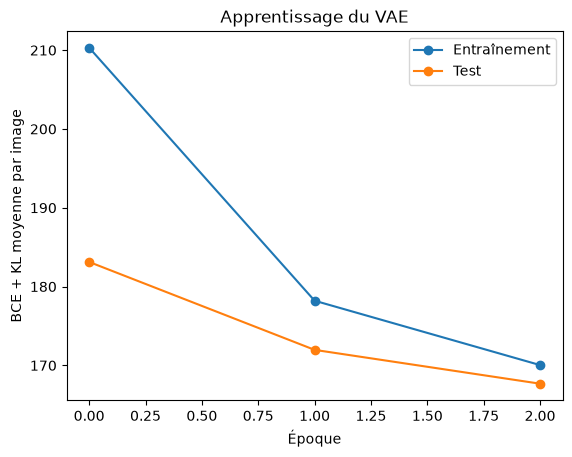

Ligne du haut : images originales ; ligne du bas : reconstructions du VAE


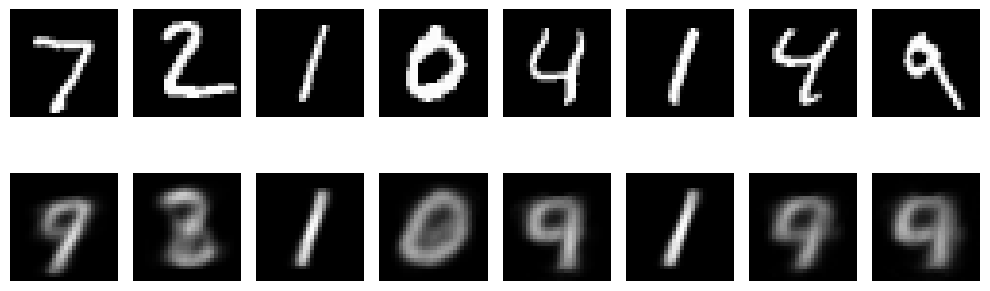

In [10]:
plt.plot(vae_train_losses, marker="o", label="Entraînement")
plt.plot(vae_test_losses, marker="o", label="Test")
plt.xlabel("Époque")
plt.ylabel("BCE + KL moyenne par image")
plt.title("Apprentissage du VAE")
plt.legend()
plt.show()

vae.eval()
with torch.inference_mode():
    vae_reconstructions, _, _ = vae(sample_images.to(device))
print("Ligne du haut : images originales ; ligne du bas : reconstructions du VAE")
show_images(torch.cat([sample_images[:8], vae_reconstructions[:8].cpu()]), columns=8, figsize=(10, 4))

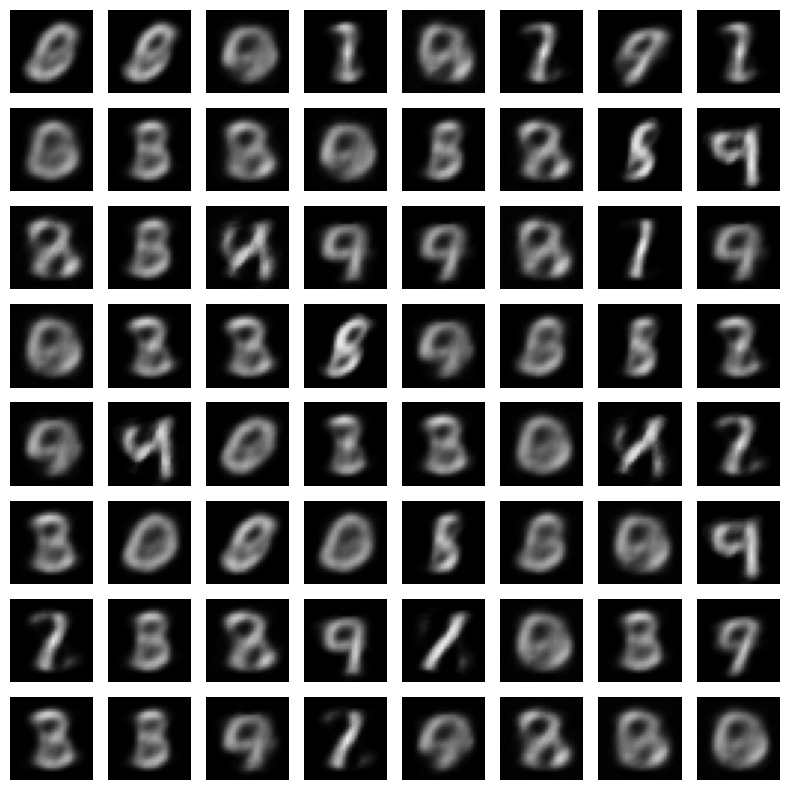

In [11]:
# Générer des chiffres en décodant des points tirés de la loi normale N(0, I).
vae.eval()
with torch.inference_mode():
    z_samples = torch.randn(64, LATENT_DIM, device=device)
    generated_images = vae.decode(z_samples)
show_images(generated_images, columns=8, figsize=(8, 8))

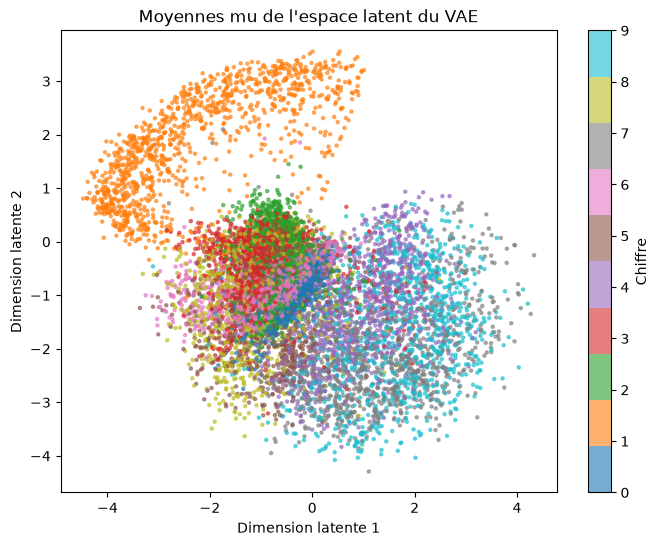

In [12]:
# Espace latent 2D : chaque point est la moyenne mu prédite pour une image de test.
vae.eval()
vae_mu_batches, vae_label_batches = [], []
with torch.inference_mode():
    for batch_images, batch_labels in test_loader:
        mu, _ = vae.encode(batch_images.to(device))
        vae_mu_batches.append(mu.cpu())
        vae_label_batches.append(batch_labels)
vae_mus = torch.cat(vae_mu_batches)
vae_labels = torch.cat(vae_label_batches)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(vae_mus[:, 0], vae_mus[:, 1], c=vae_labels, s=5, cmap="tab10", alpha=0.6)
plt.colorbar(scatter, ticks=range(10), label="Chiffre")
plt.title("Moyennes mu de l'espace latent du VAE")
plt.xlabel("Dimension latente 1")
plt.ylabel("Dimension latente 2")
plt.show()

## Bilan et questions

1. Quelle est l'exactitude du classificateur sur le jeu de test ? Quelles confusions la matrice révèle-t-elle ?
2. Comparez les reconstructions de l'auto-encodeur et du VAE. Que perd-on en compressant les images ?
3. Pourquoi le VAE régularise-t-il l'espace latent avec une divergence KL ?
4. Comment les images générées changent-elles lorsqu'on augmente le nombre d'époques ou la dimension latente ?
5. Comparez les courbes entraînement/test et discutez de la généralisation des modèles.